# Film Junky Union: análisis integral de reseñas IMDb

Film Junky Union busca convertir el lenguaje espontáneo de su comunidad en evidencia útil para explorar el catálogo y apoyar la moderación. Este análisis estudia cómo se distribuyen las opiniones de IMDb entre películas, géneros y periodos de estreno; además, valida si el texto de una reseña permite detectar automáticamente críticas negativas antes de su publicación o revisión manual.

La unidad de análisis es una reseña asociada a una película. El trabajo separa con claridad la evidencia descriptiva de la capacidad predictiva: los patrones del catálogo ayudan a comprender esta muestra, mientras que el modelo únicamente estima el sentimiento de un texto nuevo.

## Objetivos

1. **Caracterizar el catálogo y las reseñas:** medir cobertura, distribución de películas, años, géneros, duración, popularidad y sentimiento.
2. **Diagnosticar calidad y riesgos:** identificar faltantes, duplicados, valores extremos y posibles fugas de información antes de modelar.
3. **Comparar asociaciones descriptivas:** cuantificar diferencias de sentimiento por género y metadatos, sin atribuir causalidad.
4. **Validar un filtro de críticas negativas:** comparar baselines y modelos NLP que usan exclusivamente `review`, con F1 negativa >= 0.85 en el test oficial.
5. **Delimitar la transición a un MVP:** documentar qué puede automatizarse y qué datos adicionales se necesitan para recomendación personalizada o análisis temporal.

- **Usuario principal:** equipo de Film Junky Union que explora el catálogo y modera nuevas reseñas.
- **Decisión respaldada:** priorizar para revisión una reseña que el modelo estime negativa.
- **Límites:** los resultados por género, año o metadatos son descriptivos/asociativos; no demuestran causalidad ni tendencias temporales de publicación.


## Fuente, alcance y dependencias

Se usa exclusivamente `data/imdb_reviews.tsv`. Los archivos `imdb_part_1.tsv` a `imdb_part_4.tsv` son particiones del mismo contenido y no se combinan con el archivo completo. Los datos crudos no se modifican.

El entorno se gestiona con **uv**, `pyproject.toml` y `uv.lock`; el proyecto usa Python 3.12 y las versiones exactas se imprimen al ejecutar el notebook.

## Diccionario de datos

| Campo | Tipo / rol | Descripción y uso en este análisis |
|---|---|---|
| `tconst` | Identificador | ID estable de IMDb para la película; permite contar reseñas por título. |
| `title_type` | Categórica | Tipo de título; en esta muestra representa películas. |
| `primary_title`, `original_title` | Texto descriptivo | Títulos de exhibición; solo contexto, excluidos del modelo para evitar memorización por película. |
| `start_year`, `end_year` | Temporal descriptiva | Año de estreno y fin de emisión. `end_year` es estructuralmente ausente para películas y no se imputa. |
| `runtime_minutes` | Numérica descriptiva | Duración de la película; se explora con extremos visibles, no se usa para clasificar texto. |
| `is_adult`, `genres` | Categórica descriptiva | Clasificación adulta y géneros IMDb; se usan para segmentación descriptiva. |
| `average_rating`, `votes` | Numérica descriptiva | Rating agregado y cantidad de votos IMDb; se analizan como asociaciones y se excluyen del modelo por disponibilidad futura incierta. |
| `review` | Texto de entrada | Reseña escrita por una persona; única variable de entrada del modelo. |
| `rating` | Resultado/proxy | Calificación individual; no se usa porque determina directamente el sentimiento etiquetado. |
| `pos`, `sp` | Target/proxy | Etiqueta binaria positiva y su versión textual. Se conserva para auditoría, pero no entra como feature. |
| `is_negative` | Target derivado | `1 - pos`; target operativo: 1 para crítica negativa y 0 en caso contrario. |
| `ds_part` | Partición | Define train/test oficiales; nunca entra como feature. |
| `idx` | Índice técnico | Identificador de origen sin valor analítico ni predictivo. |


In [1]:
from pathlib import Path
from time import perf_counter
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='deep')
candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in candidates if (p / 'data' / 'imdb_reviews.tsv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('No se encontró data/imdb_reviews.tsv desde el directorio de trabajo actual.')
DATA_PATH = PROJECT_ROOT / 'data' / 'imdb_reviews.tsv'
print(f'Python: {platform.python_version()}')
print(f'pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}')
print(f'Fuente: {DATA_PATH.relative_to(PROJECT_ROOT)}')

Python: 3.12.3
pandas: 3.1.0 | scikit-learn: 1.9.1
Fuente: data/imdb_reviews.tsv


## Carga y contrato de datos

`pos` es el label provisto: 1 positiva y 0 negativa. Para alinear la métrica con la decisión operativa se crea `is_negative = 1 - pos`; este es el único target del modelo. `ds_part` define las particiones oficiales y no es una variable predictora.

**Resultado de carga.** La fuente contiene **47,331 reseñas de 6,648 películas**. El conjunto está diseñado para polaridad extrema: ratings 1–4 corresponden a negativas y 7–10 a no negativas; no existen ratings 5–6. Por ello el modelo responde si una reseña pertenece a una opinión claramente negativa, no si es neutral o ambivalente.

In [2]:
EXPECTED_COLUMNS = {'tconst', 'title_type', 'primary_title', 'original_title', 'start_year', 'end_year', 'runtime_minutes', 'is_adult', 'genres', 'average_rating', 'votes', 'review', 'rating', 'sp', 'pos', 'ds_part', 'idx'}
raw_reviews = pd.read_csv(DATA_PATH, sep='\t', na_values=r'\N', low_memory=False)
missing_columns = EXPECTED_COLUMNS.difference(raw_reviews.columns)
assert not missing_columns, f'Columnas requeridas ausentes: {missing_columns}'
assert raw_reviews['review'].notna().all(), 'El texto de reseña no debe faltar.'
assert set(raw_reviews['ds_part'].dropna()) == {'train', 'test'}, 'Partición inesperada.'
assert set(raw_reviews['pos'].dropna()) == {0, 1}, 'Target pos fuera de dominio.'
raw_reviews = raw_reviews.assign(is_negative=1 - raw_reviews['pos'].astype(int))
print(f'Filas: {len(raw_reviews):,} | Películas: {raw_reviews.tconst.nunique():,}')
display(raw_reviews.head(3))
display(raw_reviews.dtypes.rename('dtype').to_frame())

Filas: 47,331 | Películas: 6,648


,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx,is_negative
0,tt0068152,movie,$,$,1971,NaN,121.0,0,"Comedy,Crime,Drama",6.3,2218.0,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335,1
1,tt0068152,movie,$,$,1971,NaN,121.0,0,"Comedy,Crime,Drama",6.3,2218.0,How the hell did they get this made?! Presenti...,1,neg,0,train,8336,1
2,tt0313150,short,'15','15',2002,NaN,25.0,0,"Comedy,Drama,Short",6.3,184.0,There is no real story the film seems more lik...,3,neg,0,test,2489,1


,dtype
tconst,str
title_type,str
primary_title,str
original_title,str
start_year,int64
end_year,float64
runtime_minutes,float64
is_adult,int64
genres,str
average_rating,float64


## Calidad y vistas de trabajo

La vista diagnóstica conserva todos los valores. `end_year` se excluye de análisis posteriores porque su ausencia es estructural para películas; no se imputa. Duración y género se conservan con sus faltantes visibles. La duración extrema se marca para revisión, no se reemplaza.

**Hallazgo de calidad.** `end_year` falta en 95.2% de los registros por la naturaleza de las películas; duración falta en 1.0% y género en 0.05%. No hay filas idénticas, pero existen 91 textos repetidos, 33 duraciones de un minuto o menos y 276 de 300 minutos o más. Son señales para revisión, no errores confirmados.

Para modelado se elimina del **train** toda reseña con texto duplicado dentro de train o repetido en test; se excluyeron 39 filas. El test oficial conserva sus 23,535 filas intactas. Esta regla reduce fuga literal de texto y queda separada de la vista descriptiva.

In [3]:
missingness = (raw_reviews.isna().mean().mul(100).rename('missing_pct').to_frame().assign(missing_n=raw_reviews.isna().sum()).sort_values('missing_pct', ascending=False))
display(missingness)
quality_summary = pd.DataFrame({'metric': ['filas exactas duplicadas', 'textos de reseña duplicados', 'duración <= 1 min', 'duración >= 300 min'], 'count': [raw_reviews.duplicated().sum(), raw_reviews['review'].duplicated().sum(), raw_reviews['runtime_minutes'].le(1).sum(), raw_reviews['runtime_minutes'].ge(300).sum()]})
display(quality_summary)
train_raw = raw_reviews.loc[raw_reviews['ds_part'].eq('train')].copy()
test = raw_reviews.loc[raw_reviews['ds_part'].eq('test')].copy()
assert train_raw['tconst'].isin(test['tconst']).sum() <= 30, 'Revisar solapamiento inusual de películas.'
test_texts = set(test['review'])
train_keep = ~train_raw['review'].duplicated(keep='first') & ~train_raw['review'].isin(test_texts)
train_model = train_raw.loc[train_keep].copy()
print(f'Train original: {len(train_raw):,}; train para modelo: {len(train_model):,}; filas excluidas: {(~train_keep).sum():,}')
print(f'Test preservado: {len(test):,}; textos idénticos train-test detectados: {train_raw.review.isin(test_texts).sum():,}')
assert len(test) == raw_reviews['ds_part'].eq('test').sum(), 'El test fue alterado.'

,missing_pct,missing_n
end_year,95.184974,45052
runtime_minutes,1.031037,488
genres,0.054932,26
average_rating,0.004226,2
votes,0.004226,2
tconst,0.000000,0
title_type,0.000000,0
start_year,0.000000,0
primary_title,0.000000,0
original_title,0.000000,0


,metric,count
0,filas exactas duplicadas,0
1,textos de reseña duplicados,91
2,duración <= 1 min,33
3,duración >= 300 min,276


Train original: 23,796; train para modelo: 23,757; filas excluidas: 39
Test preservado: 23,535; textos idénticos train-test detectados: 1


## Exploración descriptiva del catálogo

**Pregunta:** ¿cómo se distribuyen las reseñas y qué segmentos del catálogo concentran mayor proporción de críticas negativas?

**Resultado global.** El sentimiento está prácticamente balanceado: 50.1% de negativas tanto en train como en test. La cobertura por título es desigual: la mediana es de 4 reseñas, el percentil 95 es 30 y ningún título supera 30. Por eso los rankings posteriores exigen un mínimo de reseñas y no deben interpretarse como un consenso total de IMDb.

Las visualizaciones describen esta muestra; no miden el efecto causal de un género, año o duración.

,reseñas,películas,tasa_negativa
ds_part,,,
test,23535,3366,50.15
train,23796,3283,50.06


count    6648.00
mean        7.12
std         7.99
min         1.00
25%         2.00
50%         4.00
75%         8.00
95%        30.00
max        30.00
dtype: float64


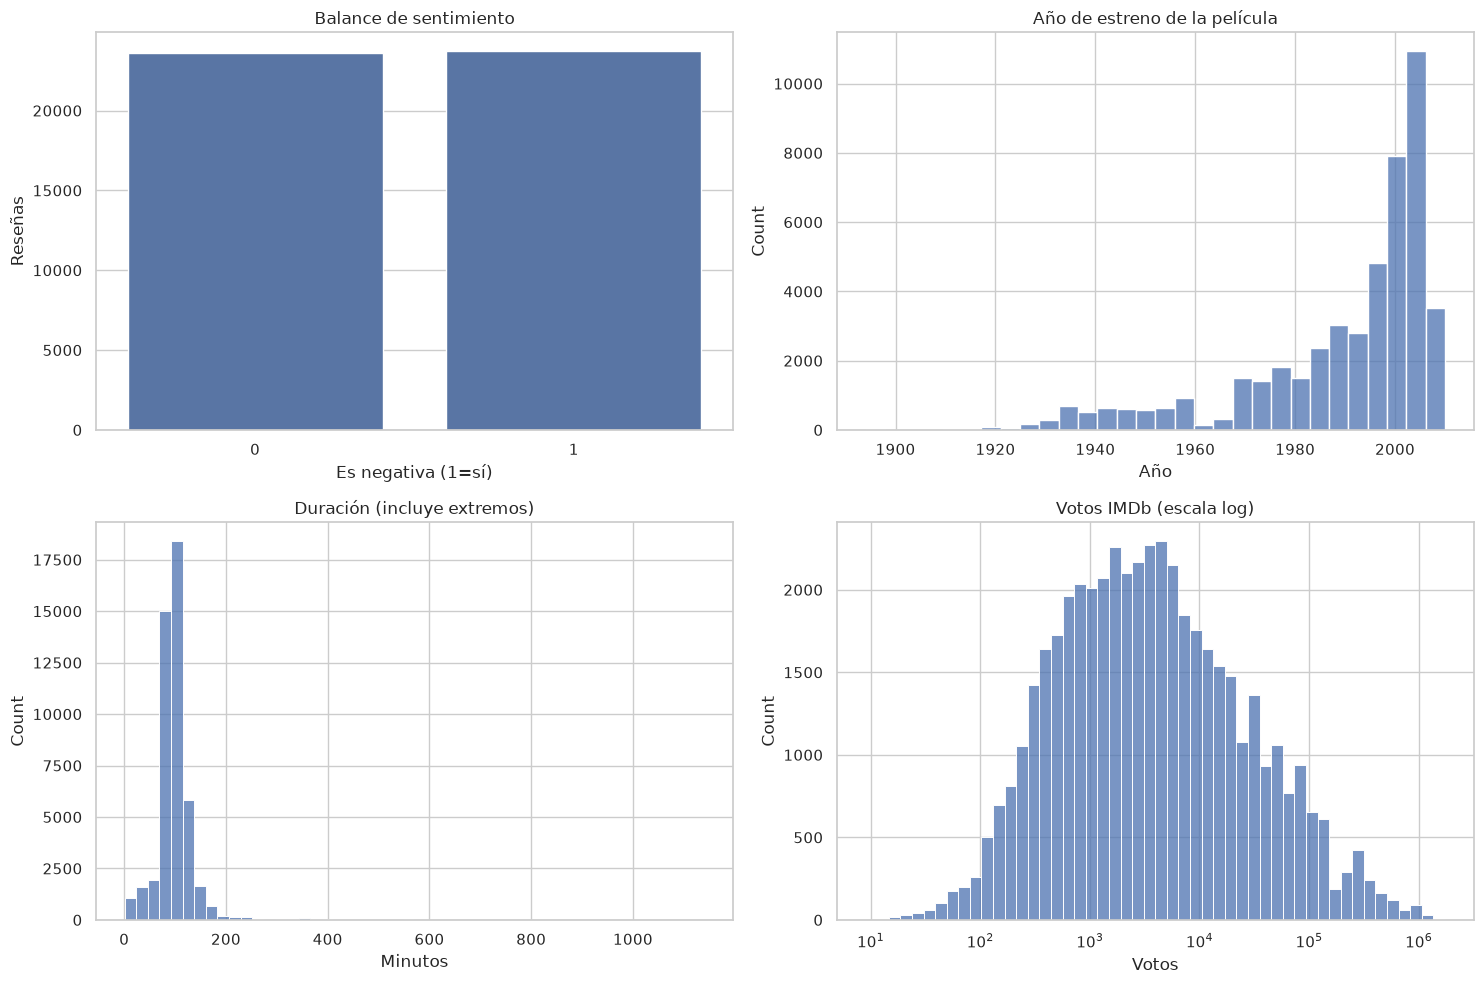

In [4]:
split_summary = (raw_reviews.groupby('ds_part', observed=True).agg(reseñas=('review', 'size'), películas=('tconst', 'nunique'), tasa_negativa=('is_negative', 'mean')).assign(tasa_negativa=lambda x: x.tasa_negativa.mul(100).round(2)))
display(split_summary)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.countplot(data=raw_reviews, x='is_negative', ax=axes[0, 0])
axes[0, 0].set(title='Balance de sentimiento', xlabel='Es negativa (1=sí)', ylabel='Reseñas')
sns.histplot(data=raw_reviews, x='start_year', bins=30, ax=axes[0, 1])
axes[0, 1].set(title='Año de estreno de la película', xlabel='Año')
sns.histplot(data=raw_reviews, x='runtime_minutes', bins=50, ax=axes[1, 0])
axes[1, 0].set(title='Duración (incluye extremos)', xlabel='Minutos')
sns.histplot(data=raw_reviews, x='votes', bins=50, log_scale=True, ax=axes[1, 1])
axes[1, 1].set(title='Votos IMDb (escala log)', xlabel='Votos')
plt.tight_layout()
review_counts = raw_reviews.groupby('tconst').size()
print(review_counts.describe(percentiles=[.25, .5, .75, .95]).round(2))

,reseñas,películas,tasa_negativa
genre,,,
Horror,8524,939,70.88
Sci-Fi,3562,424,64.94
Action,8657,1130,60.83
Thriller,6831,829,58.79
Mystery,3550,487,55.32
Adventure,5820,761,52.32
Fantasy,3926,420,50.87
Crime,7091,925,47.81
Comedy,15140,2104,46.78


is_negative,no_negativa,negativa,diferencia_negativa_menos_no_negativa
start_year,1986.06,1993.18,7.12
runtime_minutes,100.65,96.88,-3.77
average_rating,6.72,5.28,-1.44
votes,29953.57,21190.96,-8762.62


Asociación de Spearman entre rating medio IMDb y reseña negativa: -0.494


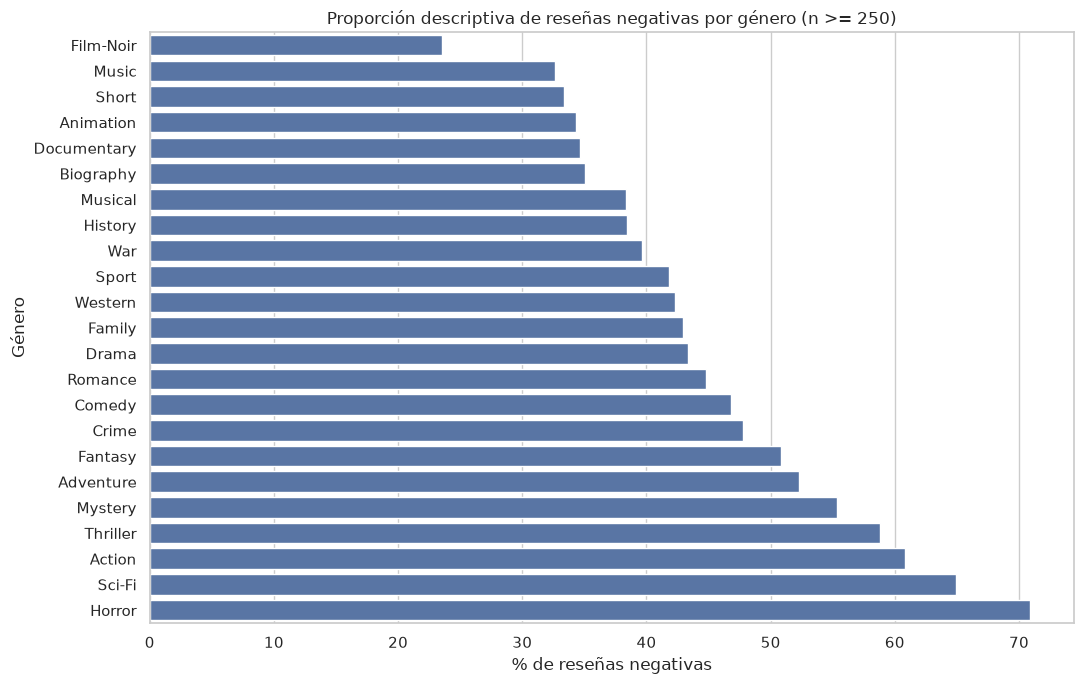

In [5]:
genre_reviews = raw_reviews.assign(genre=raw_reviews['genres'].fillna('Sin género').str.split(',')).explode('genre')
genre_summary = (genre_reviews.groupby('genre', observed=True).agg(reseñas=('is_negative', 'size'), películas=('tconst', 'nunique'), tasa_negativa=('is_negative', 'mean')).query('reseñas >= 250').sort_values('tasa_negativa', ascending=False))
genre_summary['tasa_negativa'] = genre_summary['tasa_negativa'].mul(100)
display(genre_summary.round(2))
plt.figure(figsize=(11, 7))
plot_data = genre_summary.sort_values('tasa_negativa')
sns.barplot(data=plot_data, x='tasa_negativa', y=plot_data.index, color='#4C72B0')
plt.title('Proporción descriptiva de reseñas negativas por género (n >= 250)')
plt.xlabel('% de reseñas negativas')
plt.ylabel('Género')
plt.tight_layout()
association = raw_reviews.groupby('is_negative', observed=True)[['start_year', 'runtime_minutes', 'average_rating', 'votes']].mean().T.rename(columns={0: 'no_negativa', 1: 'negativa'})
association['diferencia_negativa_menos_no_negativa'] = association['negativa'] - association['no_negativa']
display(association.round(2))
print('Asociación de Spearman entre rating medio IMDb y reseña negativa:', round(raw_reviews[['average_rating', 'is_negative']].corr(method='spearman').iloc[0, 1], 3))

## Diseño predictivo sin fuga

Las columnas `pos`, `sp`, `rating`, `ds_part`, `idx`, títulos, género y metadatos IMDb se excluyen del modelo. `rating` y `sp` son proxies directos del target; `average_rating` y `votes` pueden no estar disponibles al recibir una reseña nueva.

Esta exclusión es decisiva: `rating` y `sp` permitirían una respuesta casi perfecta por fuga, pero no estarían disponibles como evidencia textual al moderar una reseña nueva.

La selección se hace con validación cruzada estratificada solo dentro de train. Los vectorizadores se ajustan dentro de cada pipeline y el test oficial se reserva para la evaluación final.

In [6]:
X_train = train_model['review'].fillna('').str.replace(r'\s+', ' ', regex=True).str.strip()
y_train = train_model['is_negative']
X_test = test['review'].fillna('').str.replace(r'\s+', ' ', regex=True).str.strip()
y_test = test['is_negative']
assert not X_train.isin(X_test).any(), 'Persisten textos train-test idénticos.'
assert X_train.index.isin(test.index).sum() == 0, 'Solapamiento de índices entre train y test.'
assert set(y_train.unique()) == {0, 1} and set(y_test.unique()) == {0, 1}
models = {'Baseline mayoritaria': DummyClassifier(strategy='most_frequent'), 'Count + LogisticRegression': Pipeline([('vectorizer', CountVectorizer(stop_words='english', min_df=2)), ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE))]), 'TF-IDF (1,2) + LogisticRegression': Pipeline([('vectorizer', TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE))]), 'TF-IDF (1,2) + LinearSVC': Pipeline([('vectorizer', TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ('classifier', LinearSVC(C=1.0, random_state=RANDOM_STATE))])}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = {'f1_negative': 'f1', 'precision_negative': 'precision', 'recall_negative': 'recall', 'accuracy': 'accuracy'}
cv_rows = []
for name, model in models.items():
    started = perf_counter()
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
    cv_rows.append({'modelo': name, **{metric.replace('test_', ''): np.mean(value) for metric, value in scores.items() if metric.startswith('test_')}, 'segundos_cv': perf_counter() - started})
cv_results = pd.DataFrame(cv_rows).sort_values('f1_negative', ascending=False).reset_index(drop=True)
display(cv_results.style.format({'f1_negative': '{:.3f}', 'precision_negative': '{:.3f}', 'recall_negative': '{:.3f}', 'accuracy': '{:.3f}', 'segundos_cv': '{:.1f}'}))
selected_name = cv_results.loc[0, 'modelo']
selected_model = models[selected_name]
print(f'Modelo seleccionado por F1 CV: {selected_name}')

,modelo,f1_negative,precision_negative,recall_negative,accuracy,segundos_cv
0,"TF-IDF (1,2) + LinearSVC",0.894,0.903,0.885,0.895,5.9
1,"TF-IDF (1,2) + LogisticRegression",0.883,0.898,0.869,0.885,6.1
2,Count + LogisticRegression,0.872,0.879,0.866,0.873,3.7
3,Baseline mayoritaria,0.667,0.501,1.000,0.501,1.3


Modelo seleccionado por F1 CV: TF-IDF (1,2) + LinearSVC


## Evaluación final en test oficial

El modelo seleccionado fue **TF-IDF con unigramas/bigramas + LinearSVC**. En 23,535 reseñas de test obtuvo **F1 negativa = 0.890**, precision = 0.886, recall = 0.893 y accuracy = 0.889; supera la meta de F1 >= 0.85.

Interpretación: el filtro captura cerca de 89 de cada 100 críticas negativas y, entre las que marca como negativas, alrededor de 89 de cada 100 lo son. Los errores mostrados son importantes para moderación: textos mixtos, comparativos o irónicos pueden necesitar revisión humana. El resultado es predictivo, no causal.

,valor
F1 negativa,0.890
Precision negativa,0.886
Recall negativa,0.893
Accuracy,0.889
segundos ajuste + inferencia,8.385


Criterio F1 negativa >= 0.85: APROBADO
              precision    recall  f1-score   support

 no negativa      0.892     0.885     0.888     11732
    negativa      0.886     0.893     0.890     11803

    accuracy                          0.889     23535
   macro avg      0.889     0.889     0.889     23535
weighted avg      0.889     0.889     0.889     23535



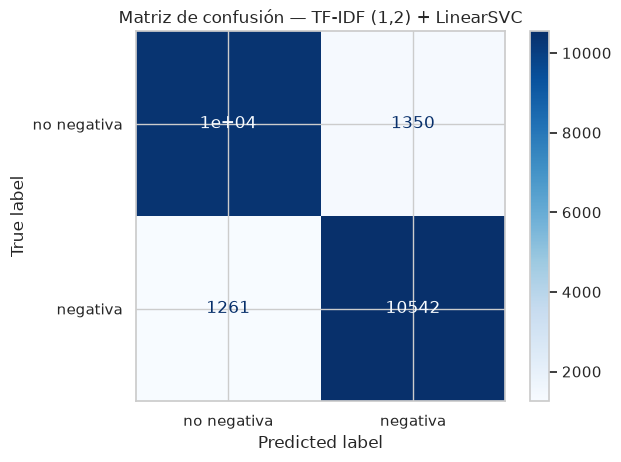

Falsos negativos: críticas negativas no filtradas


,review,genres,start_year
15,I caught the North American premiere of this a...,"Crime,Drama,Thriller",2001
23,Below average blaxpoitation action / melodrama...,"Action,Crime,Drama",1975
399,"Well well, I had seen a lot of reviews on this...",Horror,1988


Falsos positivos: críticas no negativas filtradas


,review,genres,start_year
26,Sheba Baby is always underrated most likely be...,"Action,Crime,Drama",1975
28,"Yeah, I guess this movie is kinda dull compare...","Action,Crime,Drama",1975
40,i consider this movie as one of the most inter...,Comedy,1994


In [7]:
started = perf_counter()
selected_model.fit(X_train, y_train)
y_pred = selected_model.predict(X_test)
test_seconds = perf_counter() - started
test_metrics = pd.Series({'F1 negativa': f1_score(y_test, y_pred, pos_label=1), 'Precision negativa': precision_score(y_test, y_pred, pos_label=1), 'Recall negativa': recall_score(y_test, y_pred, pos_label=1), 'Accuracy': accuracy_score(y_test, y_pred), 'segundos ajuste + inferencia': test_seconds})
display(test_metrics.to_frame('valor').style.format({'valor': '{:.3f}'}))
passed = test_metrics['F1 negativa'] >= 0.85
print('Criterio F1 negativa >= 0.85:', 'APROBADO' if passed else 'NO APROBADO')
print(classification_report(y_test, y_pred, target_names=['no negativa', 'negativa'], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['no negativa', 'negativa'], cmap='Blues')
plt.title(f'Matriz de confusión — {selected_name}')
plt.show()
errors = test.assign(predicted_negative=y_pred)
false_negatives = errors.query('is_negative == 1 and predicted_negative == 0')[['review', 'genres', 'start_year']].head(3)
false_positives = errors.query('is_negative == 0 and predicted_negative == 1')[['review', 'genres', 'start_year']].head(3)
print('Falsos negativos: críticas negativas no filtradas')
display(false_negatives)
print('Falsos positivos: críticas no negativas filtradas')
display(false_positives)

## Exploración ampliada: ratings, décadas y popularidad

**Pregunta descriptiva:** ¿cómo cambian la composición del catálogo y la proporción de críticas negativas por década de estreno y rating individual? `start_year` es el año de la película, no la fecha en que se escribió la reseña; por tanto, esta sección no estima tendencias temporales de opinión.

**Hallazgos.** La etiqueta coincide completamente con la regla de rating: 1–4 tienen 100% de negatividad y 7–10, 0%. Entre décadas con volumen suficiente, la negatividad sube desde 29.9% en los años 1930 a 58.8% en los 2000. La década de 2010 tiene solo 27 reseñas y se excluye de cualquier conclusión.

,reseñas,tasa_negativa
rating,,
1,9589,100.0
2,4339,100.0
3,4709,100.0
4,5078,100.0
7,4593,0.0
8,5576,0.0
9,4343,0.0
10,9104,0.0


,decada,reseñas,películas,tasa_negativa,rating_imdb_medio
0,1890,22,4,4.55,6.55
1,1900,20,9,55.00,5.11
2,1910,94,32,28.72,6.34
3,1920,318,72,21.38,7.01
4,1930,1252,246,29.95,6.63
5,1940,1518,289,32.15,6.78
6,1950,2048,333,33.84,6.57
7,1960,1093,182,37.24,6.51
8,1970,4077,626,42.16,6.17
9,1980,6240,847,45.10,6.04


Nota: la relación describe la muestra IMDb; no atribuye cambios de percepción al año de estreno.


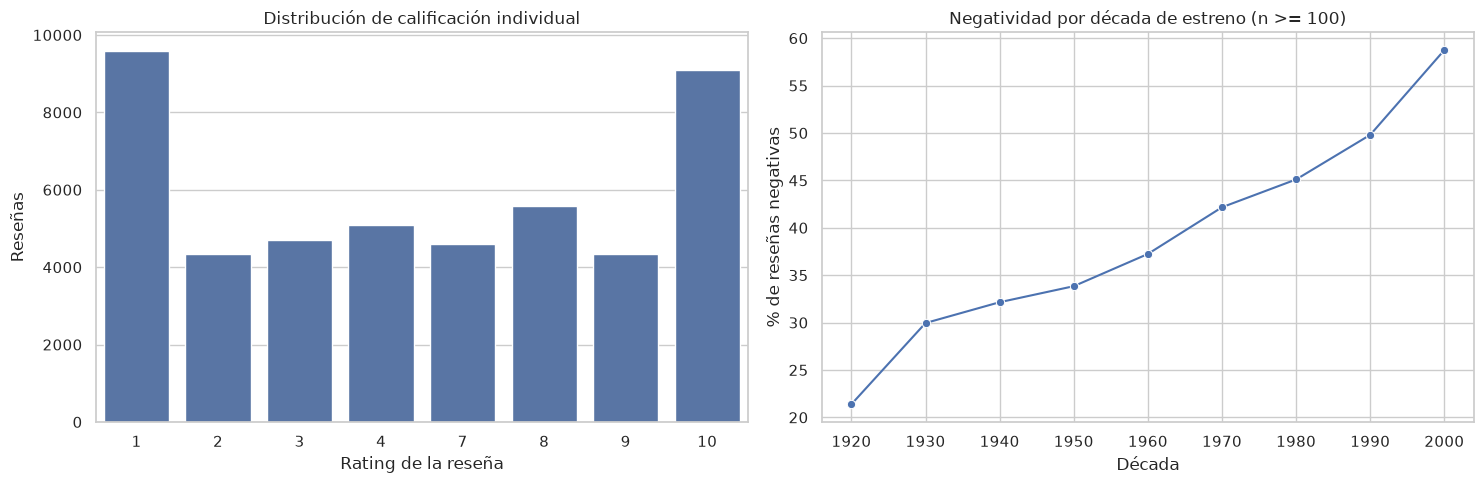

In [8]:
rating_summary = (raw_reviews.groupby('rating', observed=True).agg(reseñas=('review', 'size'), tasa_negativa=('is_negative', 'mean')).assign(tasa_negativa=lambda x: x.tasa_negativa.mul(100)))
display(rating_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=raw_reviews, x='rating', order=sorted(raw_reviews['rating'].unique()), ax=axes[0])
axes[0].set(title='Distribución de calificación individual', xlabel='Rating de la reseña', ylabel='Reseñas')
era_reviews = raw_reviews.assign(decada=(raw_reviews['start_year'] // 10 * 10).astype('Int64'))
era_summary = (era_reviews.groupby('decada', observed=True).agg(reseñas=('review', 'size'), películas=('tconst', 'nunique'), tasa_negativa=('is_negative', 'mean'), rating_imdb_medio=('average_rating', 'mean')).reset_index())
era_summary['tasa_negativa'] = era_summary['tasa_negativa'].mul(100)
display(era_summary.round(2))
sns.lineplot(data=era_summary.query('reseñas >= 100'), x='decada', y='tasa_negativa', marker='o', ax=axes[1])
axes[1].set(title='Negatividad por década de estreno (n >= 100)', xlabel='Década', ylabel='% de reseñas negativas')
plt.tight_layout()
print('Nota: la relación describe la muestra IMDb; no atribuye cambios de percepción al año de estreno.')

## Listas editoriales con respaldo de muestra

**Pregunta descriptiva:** ¿qué títulos tienen recepción marcadamente negativa, positiva o dividida? Hay 1,452 títulos con al menos 10 reseñas. Ejemplos de recepción totalmente negativa en esta muestra son *Hobgoblins*, *Hangmen* y *House of the Dead*; *Baby Face*, *Alexander Nevsky* y *The Shop Around the Corner* aparecen con 0% de negativas.

La polarización se define de forma operativa como una tasa negativa entre 40% y 60%; no representa una propiedad universal de la película. Una tasa extrema con solo 10–30 reseñas sigue siendo incierta, por lo que la sección siguiente complementa estas listas con intervalos.

In [9]:
movie_summary = (raw_reviews.groupby(['tconst', 'primary_title'], dropna=False).agg(reseñas=('review', 'size'), tasa_negativa=('is_negative', 'mean'), rating_imdb=('average_rating', 'first'), votos_imdb=('votes', 'first'), año=('start_year', 'first')).reset_index())
eligible_movies = movie_summary.query('reseñas >= 10').copy()
eligible_movies['tasa_negativa'] = eligible_movies['tasa_negativa'].mul(100)
editorial_columns = ['primary_title', 'año', 'reseñas', 'tasa_negativa', 'rating_imdb', 'votos_imdb']
print('Títulos con evidencia suficiente:', len(eligible_movies))
print('Más criticadas en esta muestra')
display(eligible_movies.sort_values(['tasa_negativa', 'reseñas'], ascending=[False, False])[editorial_columns].head(10).round(2))
print('Mejor recibidas en esta muestra')
display(eligible_movies.sort_values(['tasa_negativa', 'reseñas'], ascending=[True, False])[editorial_columns].head(10).round(2))
polarized_movies = eligible_movies.loc[eligible_movies['tasa_negativa'].between(40, 60)].copy()
polarized_movies['distancia_50'] = (polarized_movies['tasa_negativa'] - 50).abs()
print('Más divisivas: cercanas a 50% de reseñas negativas')
display(polarized_movies.sort_values(['distancia_50', 'reseñas'])[editorial_columns].head(10).round(2))
print('Asociación de Spearman entre negatividad por título y rating IMDb:', round(eligible_movies[['tasa_negativa', 'rating_imdb']].corr(method='spearman').iloc[0, 1], 3))

Títulos con evidencia suficiente: 1452
Más criticadas en esta muestra


,primary_title,año,reseñas,tasa_negativa,rating_imdb,votos_imdb
1993,Hobgoblins,1988,30,100.0,2.3,10320.0
2149,Hangmen,1987,30,100.0,3.1,966.0
4781,The Foreigner,2003,30,100.0,3.4,6226.0
4824,House of the Dead,2003,30,100.0,2.0,35516.0
5142,Christmas Vacation 2: Cousin Eddie's Island Ad...,2003,30,100.0,2.7,3060.0
5810,The Wicker Man,2006,30,100.0,3.7,63008.0
5923,Zombie Nation,2004,30,100.0,2.0,7850.0
5984,B.T.K. Killer,2005,30,100.0,1.5,1268.0
6525,Five Across the Eyes,2006,30,100.0,2.5,1597.0
6568,Prom Night,2008,30,100.0,3.9,33121.0


Mejor recibidas en esta muestra


,primary_title,año,reseñas,tasa_negativa,rating_imdb,votos_imdb
168,Baby Face,1933,30,0.0,7.6,5975.0
303,Alexander Nevsky,1938,30,0.0,7.6,10196.0
366,The Shop Around the Corner,1940,30,0.0,8.1,26465.0
368,The Thief of Bagdad,1940,30,0.0,7.5,11541.0
488,Anchors Aweigh,1945,30,0.0,7.1,7652.0
548,Crossfire,1947,30,0.0,7.3,7018.0
579,Mr. Blandings Builds His Dream House,1948,30,0.0,7.3,9904.0
641,Panic in the Streets,1950,30,0.0,7.3,6835.0
649,Where the Sidewalk Ends,1950,30,0.0,7.6,7370.0
650,Winchester '73,1950,30,0.0,7.6,16158.0


Más divisivas: cercanas a 50% de reseñas negativas


,primary_title,año,reseñas,tasa_negativa,rating_imdb,votos_imdb
1346,Enter the Devil,1974,10,50.0,4.7,473.0
1392,"'Sheba, Baby'",1975,10,50.0,5.8,1204.0
1716,Heartbeeps,1981,12,50.0,4.2,1279.0
2998,Public Enemies,1996,12,50.0,4.1,979.0
1421,The Last Hard Men,1976,14,50.0,6.2,1871.0
1937,Protocol,1984,14,50.0,5.5,4365.0
4708,The President's Man: A Line in the Sand,2002,14,50.0,4.4,1128.0
2215,D.O.A.,1988,16,50.0,6.2,9261.0
5045,Carmen,2003,16,50.0,6.1,1902.0
710,Jack and the Beanstalk,1952,20,50.0,6.0,2737.0


Asociación de Spearman entre negatividad por título y rating IMDb: -0.72


## Lenguaje que diferencia reseñas positivas y negativas

**Pregunta exploratoria:** ¿qué términos y frases aparecen con mayor frecuencia dentro de cada sentimiento? En negativas destacan `bad`, `plot` y `acting`; en no negativas aparecen `good`, `great`, `love` y `best`. Términos como `movie`, `film` y `story` son comunes en ambos grupos, por lo que la frecuencia bruta no basta para considerarlos señales de sentimiento.

Los resultados son indicios léxicos de esta muestra, no explicaciones causales ni reglas de moderación. Se excluyen palabras vacías inglesas y se exige una frecuencia mínima para reducir ruido.

,término,frecuencia,sentimiento
0,movie,47798,negativa
1,film,35823,negativa
2,like,21334,negativa
3,just,20020,negativa
4,bad,14040,negativa
5,good,14014,negativa
6,really,11723,negativa
7,time,11704,negativa
8,don,10107,negativa
9,story,9696,negativa


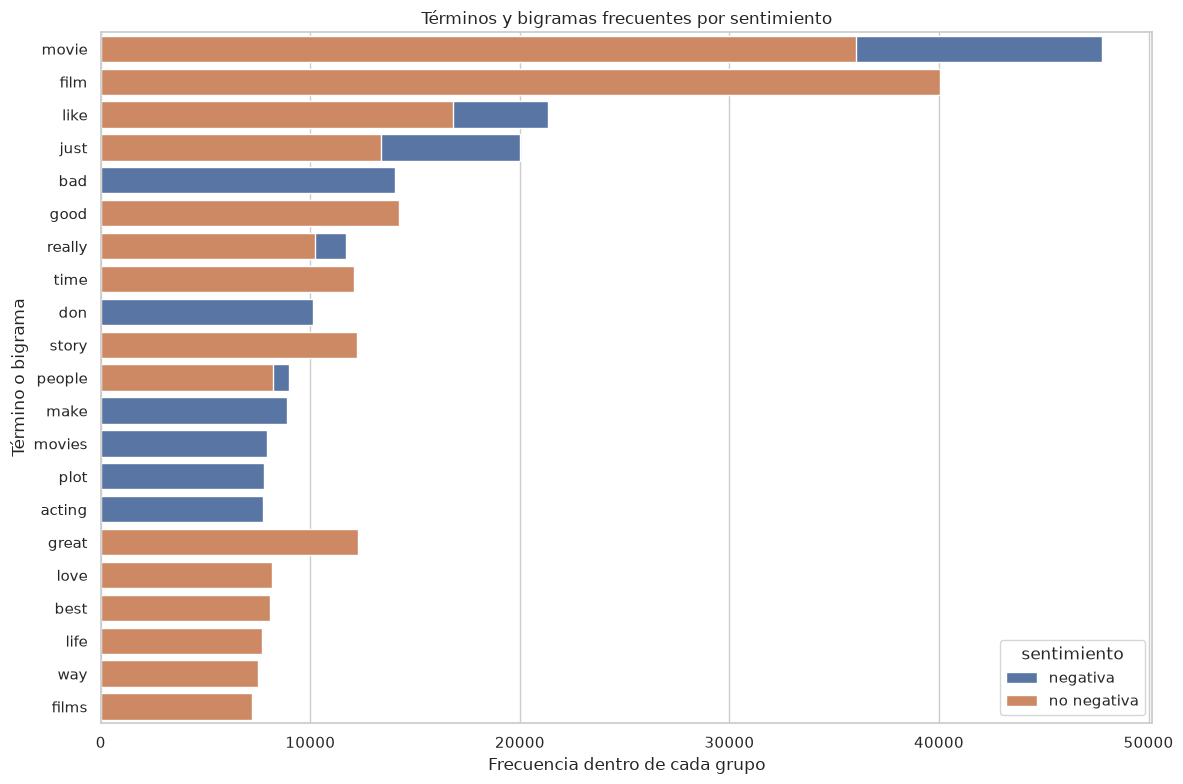

In [10]:
def top_ngrams(texts, label, n=15):
    vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=20)
    matrix = vectorizer.fit_transform(texts)
    frequencies = np.asarray(matrix.sum(axis=0)).ravel()
    terms = np.asarray(vectorizer.get_feature_names_out())
    return (pd.DataFrame({'término': terms, 'frecuencia': frequencies, 'sentimiento': label})
            .sort_values('frecuencia', ascending=False).head(n))

negative_terms = top_ngrams(raw_reviews.loc[raw_reviews['is_negative'].eq(1), 'review'], 'negativa')
positive_terms = top_ngrams(raw_reviews.loc[raw_reviews['is_negative'].eq(0), 'review'], 'no negativa')
top_terms = pd.concat([negative_terms, positive_terms], ignore_index=True)
display(top_terms)
plt.figure(figsize=(12, 8))
sns.barplot(data=top_terms, x='frecuencia', y='término', hue='sentimiento', dodge=False)
plt.title('Términos y bigramas frecuentes por sentimiento')
plt.xlabel('Frecuencia dentro de cada grupo')
plt.ylabel('Término o bigrama')
plt.tight_layout()

## Robustez del clasificador por segmento

**Pregunta predictiva:** ¿el rendimiento cambia de manera relevante entre segmentos observables? El modelo es especialmente sólido en Horror (F1 0.922), Action (0.912), Sci‑Fi (0.911) y Thriller (0.910), pero baja en Documentary (0.780), Music (0.793), Short (0.802) y Animation (0.811). Por década, el punto más débil es 1930 (F1 0.749); por longitud de reseña, el F1 se mantiene estable entre 0.887 y 0.893.

Conclusión operativa: los géneros y décadas de menor rendimiento son candidatos a revisión humana reforzada. La evaluación usa únicamente el test oficial ya reservado. Los géneros se explotan porque una reseña puede pertenecer a varios; por ello los resultados por género no son mutuamente excluyentes. Se omiten segmentos con menos de 200 reseñas o con una sola clase.

Rendimiento por género


,segmento,reseñas,F1 negativa,precision negativa,recall negativa
6,Documentary,691,0.780,0.772,0.789
12,Music,818,0.793,0.824,0.764
17,Short,316,0.802,0.837,0.770
2,Animation,837,0.811,0.792,0.831
20,War,680,0.825,0.809,0.842
8,Family,1329,0.848,0.855,0.841
3,Biography,905,0.850,0.898,0.808
21,Western,440,0.852,0.850,0.855
10,History,604,0.862,0.848,0.876
7,Drama,11125,0.876,0.884,0.868


Rendimiento por década


,segmento,reseñas,F1 negativa,precision negativa,recall negativa
0,1930,483,0.749,0.812,0.695
1,1940,731,0.783,0.804,0.763
2,1950,1069,0.814,0.821,0.808
4,1970,2062,0.834,0.803,0.868
3,1960,555,0.836,0.847,0.826
5,1980,2960,0.865,0.848,0.882
6,1990,5358,0.898,0.892,0.905
7,2000,10041,0.917,0.918,0.915


Rendimiento por longitud de reseña


,segmento,reseñas,F1 negativa,precision negativa,recall negativa
0,"(3.999, 125.0]",5982,0.887,0.887,0.887
2,"(171.0, 275.0]",5819,0.888,0.881,0.894
3,"(275.0, 2235.0]",5866,0.891,0.882,0.901
1,"(125.0, 171.0]",5868,0.893,0.896,0.890


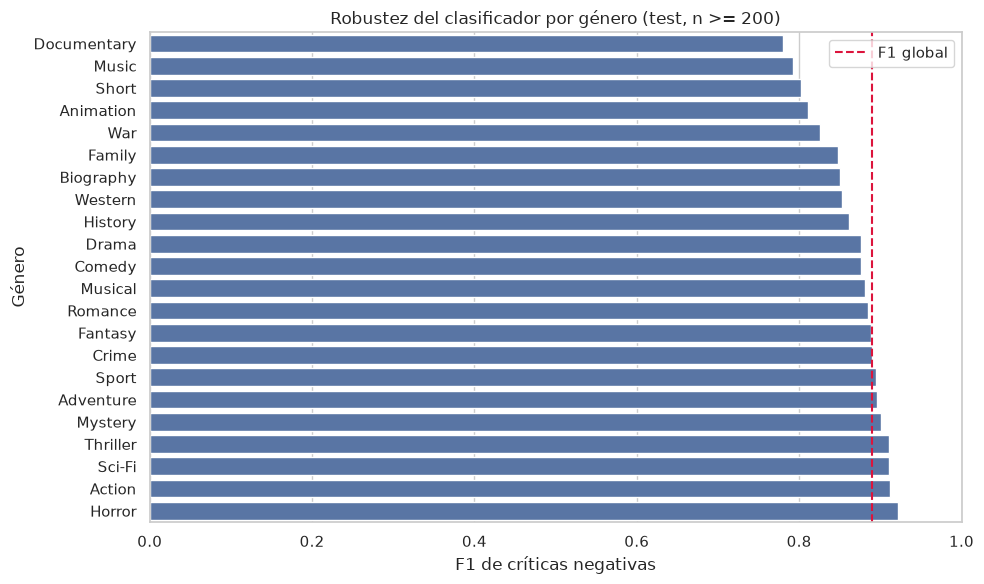

In [11]:
def metrics_by_segment(frame, segment, min_n=200):
    rows = []
    for value, group in frame.groupby(segment, dropna=False, observed=True):
        if len(group) < min_n or group['is_negative'].nunique() < 2:
            continue
        rows.append({
            'segmento': str(value), 'reseñas': len(group),
            'F1 negativa': f1_score(group['is_negative'], group['predicted_negative'], pos_label=1),
            'precision negativa': precision_score(group['is_negative'], group['predicted_negative'], pos_label=1),
            'recall negativa': recall_score(group['is_negative'], group['predicted_negative'], pos_label=1),
        })
    return pd.DataFrame(rows).sort_values('F1 negativa')

test_segments = errors.copy()
test_segments['longitud_reseña'] = test_segments['review'].str.split().str.len()
test_segments['banda_longitud'] = pd.qcut(test_segments['longitud_reseña'], q=4, duplicates='drop')
test_segments['decada'] = (test_segments['start_year'] // 10 * 10).astype('Int64')
test_segments['género'] = test_segments['genres'].fillna('Sin género').str.split(',')
genre_test_segments = test_segments.explode('género')
segment_tables = {
    'género': metrics_by_segment(genre_test_segments, 'género'),
    'década': metrics_by_segment(test_segments, 'decada'),
    'longitud de reseña': metrics_by_segment(test_segments, 'banda_longitud'),
}
for name, table in segment_tables.items():
    print(f'Rendimiento por {name}')
    display(table.round(3))

plt.figure(figsize=(10, 6))
sns.barplot(data=segment_tables['género'], x='F1 negativa', y='segmento', color='#4C72B0')
plt.axvline(test_metrics['F1 negativa'], color='crimson', linestyle='--', label='F1 global')
plt.xlim(0, 1)
plt.title('Robustez del clasificador por género (test, n >= 200)')
plt.xlabel('F1 de críticas negativas')
plt.ylabel('Género')
plt.legend()
plt.tight_layout()

## Incertidumbre de la recepción por película

**Pregunta descriptiva:** ¿qué tan concluyente es la tasa negativa de cada título? Una tasa de 100% con 10 reseñas contiene mucha más incertidumbre que la misma tasa con cientos. Se calcula un intervalo de Wilson al 95% y una tasa suavizada hacia la media global; estas métricas priorizan evidencia, no cambian las etiquetas originales.


In [12]:
title_evidence = (raw_reviews.groupby(['tconst', 'primary_title'], dropna=False)
                  .agg(reseñas=('review', 'size'), negativas=('is_negative', 'sum'), rating_imdb=('average_rating', 'first'))
                  .reset_index())
title_evidence['tasa_negativa'] = title_evidence['negativas'] / title_evidence['reseñas']
z = 1.96
n = title_evidence['reseñas']
p = title_evidence['tasa_negativa']
wilson_center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
wilson_half = z * np.sqrt((p * (1 - p) / n) + z**2 / (4 * n**2)) / (1 + z**2 / n)
title_evidence['wilson_inferior'] = wilson_center - wilson_half
title_evidence['wilson_superior'] = wilson_center + wilson_half
global_negative_rate = raw_reviews['is_negative'].mean()
prior_strength = 10
title_evidence['tasa_suavizada'] = (title_evidence['negativas'] + prior_strength * global_negative_rate) / (title_evidence['reseñas'] + prior_strength)
robust_titles = title_evidence.query('reseñas >= 10').copy()
columns = ['primary_title', 'reseñas', 'tasa_negativa', 'wilson_inferior', 'wilson_superior', 'tasa_suavizada', 'rating_imdb']
print('Títulos con al menos 10 reseñas:', len(robust_titles))
print('Críticas negativas con mayor respaldo estadístico')
display(robust_titles.sort_values(['wilson_inferior', 'reseñas'], ascending=[False, False])[columns].head(10).round(3))
print('Recepción positiva con mayor respaldo estadístico')
display(robust_titles.sort_values(['wilson_superior', 'reseñas'], ascending=[True, False])[columns].head(10).round(3))
print('Interpretación: el intervalo expresa incertidumbre muestral, no calidad objetiva de una película.')

Títulos con al menos 10 reseñas: 1452
Críticas negativas con mayor respaldo estadístico


,primary_title,reseñas,tasa_negativa,wilson_inferior,wilson_superior,tasa_suavizada,rating_imdb
1993,Hobgoblins,30,1.0,0.886,1.0,0.875,2.3
2149,Hangmen,30,1.0,0.886,1.0,0.875,3.1
4781,The Foreigner,30,1.0,0.886,1.0,0.875,3.4
4824,House of the Dead,30,1.0,0.886,1.0,0.875,2.0
5142,Christmas Vacation 2: Cousin Eddie's Island Ad...,30,1.0,0.886,1.0,0.875,2.7
5810,The Wicker Man,30,1.0,0.886,1.0,0.875,3.7
5923,Zombie Nation,30,1.0,0.886,1.0,0.875,2.0
5984,B.T.K. Killer,30,1.0,0.886,1.0,0.875,1.5
6525,Five Across the Eyes,30,1.0,0.886,1.0,0.875,2.5
6568,Prom Night,30,1.0,0.886,1.0,0.875,3.9


Recepción positiva con mayor respaldo estadístico


,primary_title,reseñas,tasa_negativa,wilson_inferior,wilson_superior,tasa_suavizada,rating_imdb
168,Baby Face,30,0.0,-0.0,0.114,0.125,7.6
303,Alexander Nevsky,30,0.0,-0.0,0.114,0.125,7.6
366,The Shop Around the Corner,30,0.0,-0.0,0.114,0.125,8.1
368,The Thief of Bagdad,30,0.0,-0.0,0.114,0.125,7.5
488,Anchors Aweigh,30,0.0,-0.0,0.114,0.125,7.1
548,Crossfire,30,0.0,-0.0,0.114,0.125,7.3
579,Mr. Blandings Builds His Dream House,30,0.0,-0.0,0.114,0.125,7.3
641,Panic in the Streets,30,0.0,-0.0,0.114,0.125,7.3
649,Where the Sidewalk Ends,30,0.0,-0.0,0.114,0.125,7.6
650,Winchester '73,30,0.0,-0.0,0.114,0.125,7.6


Interpretación: el intervalo expresa incertidumbre muestral, no calidad objetiva de una película.


## Interacción exploratoria entre género y década

**Pregunta exploratoria:** ¿la negatividad de un género parece estable entre décadas? Se muestran únicamente combinaciones con al menos 100 reseñas. Las películas multigénero aparecen en cada uno de sus géneros, por lo que las celdas no son grupos excluyentes y el patrón no identifica causalidad.


,género,decada,reseñas,tasa_negativa
82,Drama,1920,179,20.11
47,Comedy,1920,124,17.74
161,Mystery,1930,126,39.68
17,Adventure,1930,190,37.89
3,Action,1930,124,32.26
...,...,...,...,...
43,Biography,2000,936,43.70
79,Documentary,2000,961,38.29
150,Music,2000,654,37.46
218,Sport,2000,473,32.98


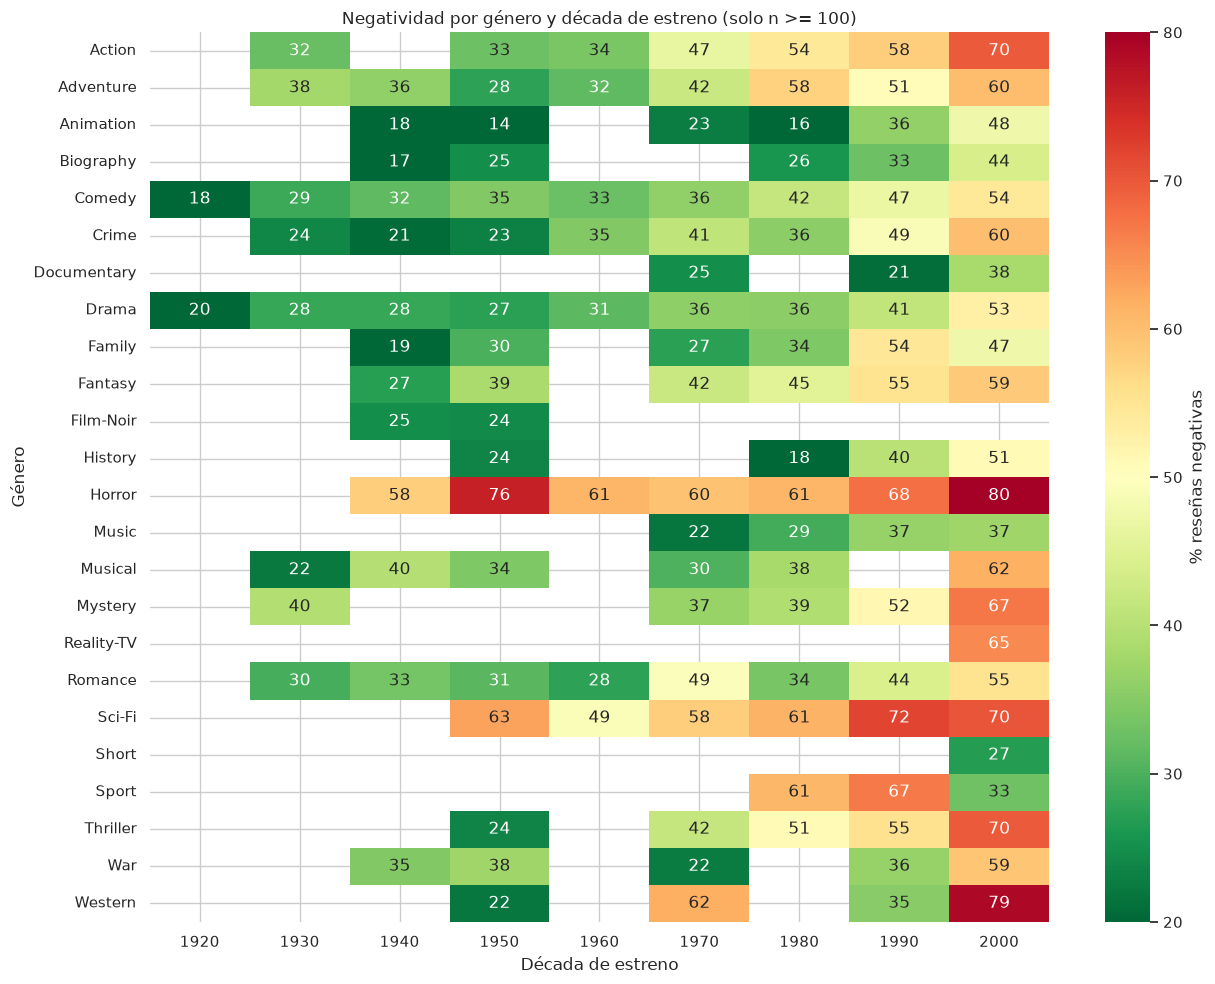

In [13]:
genre_decade = (raw_reviews.assign(género=raw_reviews['genres'].fillna('Sin género').str.split(','), decada=(raw_reviews['start_year'] // 10 * 10).astype('Int64'))
                .explode('género')
                .groupby(['género', 'decada'], observed=True)
                .agg(reseñas=('review', 'size'), tasa_negativa=('is_negative', 'mean'))
                .reset_index())
genre_decade['tasa_negativa'] = genre_decade['tasa_negativa'].mul(100)
heatmap_source = genre_decade.loc[genre_decade['reseñas'] >= 100].pivot(index='género', columns='decada', values='tasa_negativa')
display(genre_decade.loc[genre_decade['reseñas'] >= 100].sort_values(['decada', 'tasa_negativa'], ascending=[True, False]).round(2))
plt.figure(figsize=(13, 10))
sns.heatmap(heatmap_source, cmap='RdYlGn_r', vmin=20, vmax=80, annot=True, fmt='.0f', cbar_kws={'label': '% reseñas negativas'})
plt.title('Negatividad por género y década de estreno (solo n >= 100)')
plt.xlabel('Década de estreno')
plt.ylabel('Género')
plt.tight_layout()

## Vocabulario distintivo, no solo frecuente

Los conteos anteriores privilegian palabras generales como `movie` y `film`. Aquí se compara la presencia de unigramas y bigramas entre clases con suavizado logarítmico. Un valor positivo indica mayor presencia relativa en críticas negativas; uno negativo, en no negativas. Es una descripción del corpus, no una explicación de por qué una reseña recibe una etiqueta.


Marcadores relativamente más presentes en críticas negativas


,término,log_ratio_negativa,documentos_negativos,documentos_no_negativos
2002,avoid like,4.476,87,0
8292,easily worst,4.342,76,0
7909,doubt worst,4.125,61,0
17940,manos,4.109,60,0
31946,worse acting,4.059,57,0
28069,supposed comedy,4.006,54,0
579,acting awful,4.006,109,1
29490,total waste,3.949,103,1
5829,couldn save,3.930,50,0
9185,excuse film,3.869,47,0


Marcadores relativamente más presentes en reseñas no negativas


,término,log_ratio_negativa,documentos_negativos,documentos_no_negativos
23297,raoul walsh,-3.665,0,38
30871,vote seven,-3.498,0,32
8130,dull moment,-3.436,0,30
19960,nan,-3.436,0,30
25879,seven title,-3.403,0,29
15493,keeps edge,-3.369,0,28
8444,eleanor parker,-3.334,0,27
22249,ponyo,-3.298,0,26
19584,movie touching,-3.221,0,24
9140,excellent direction,-3.221,0,24


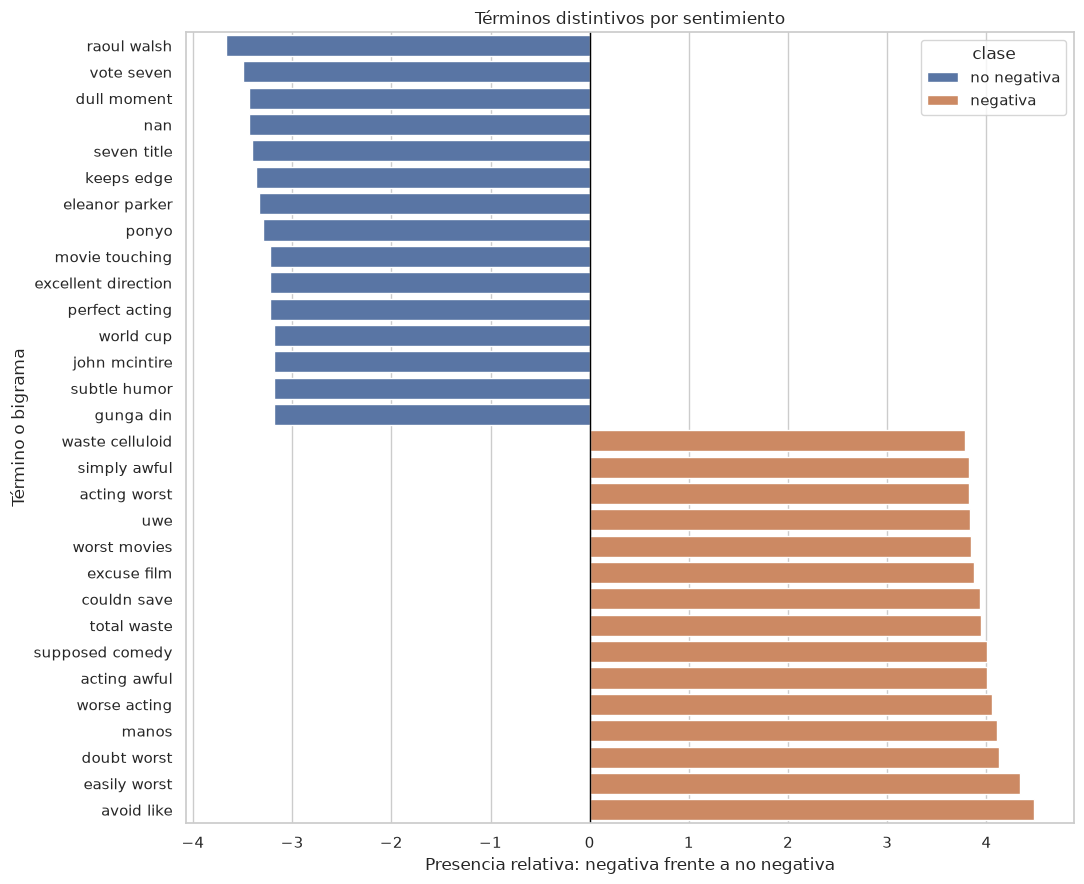

In [14]:
contrast_vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=20, binary=True)
contrast_matrix = contrast_vectorizer.fit_transform(raw_reviews['review'])
negative_mask = raw_reviews['is_negative'].to_numpy(dtype=bool)
negative_document_frequency = np.asarray(contrast_matrix[negative_mask].sum(axis=0)).ravel()
nonnegative_document_frequency = np.asarray(contrast_matrix[~negative_mask].sum(axis=0)).ravel()
vocabulary_size = contrast_matrix.shape[1]
log_ratio = np.log((negative_document_frequency + 1) / (negative_mask.sum() + vocabulary_size)) - np.log((nonnegative_document_frequency + 1) / ((~negative_mask).sum() + vocabulary_size))
term_contrast = pd.DataFrame({'término': contrast_vectorizer.get_feature_names_out(), 'log_ratio_negativa': log_ratio, 'documentos_negativos': negative_document_frequency, 'documentos_no_negativos': nonnegative_document_frequency})
negative_markers = term_contrast.sort_values('log_ratio_negativa', ascending=False).head(15)
positive_markers = term_contrast.sort_values('log_ratio_negativa').head(15)
print('Marcadores relativamente más presentes en críticas negativas')
display(negative_markers.round(3))
print('Marcadores relativamente más presentes en reseñas no negativas')
display(positive_markers.round(3))
contrast_plot = pd.concat([negative_markers.assign(clase='negativa'), positive_markers.assign(clase='no negativa')]).sort_values('log_ratio_negativa')
plt.figure(figsize=(11, 9))
sns.barplot(data=contrast_plot, x='log_ratio_negativa', y='término', hue='clase', dodge=False)
plt.axvline(0, color='black', linewidth=1)
plt.title('Términos distintivos por sentimiento')
plt.xlabel('Presencia relativa: negativa frente a no negativa')
plt.ylabel('Término o bigrama')
plt.tight_layout()

## Umbral operativo y diagnóstico de errores

**Pregunta operativa:** ¿qué margen de decisión puede priorizar reseñas negativas con alta precisión y qué características aparecen en los errores? El umbral se elige con márgenes fuera de muestra generados dentro del train mediante validación cruzada. Los márgenes de `LinearSVC` no son probabilidades calibradas: representan distancia relativa a la frontera de decisión. El test se usa solo para reportar cómo se comporta esa regla ya elegida.


In [15]:
oof_margins = np.empty(len(X_train))
for train_index, validation_index in cv.split(X_train, y_train):
    fold_model = clone(selected_model)
    fold_model.fit(X_train.iloc[train_index], y_train.iloc[train_index])
    oof_margins[validation_index] = fold_model.decision_function(X_train.iloc[validation_index])
candidate_thresholds = np.unique(np.quantile(oof_margins, [0.0, 0.25, 0.50, 0.60, 0.70, 0.80, 0.90]))
threshold_rows = []
for threshold in candidate_thresholds:
    oof_prediction = (oof_margins >= threshold).astype(int)
    threshold_rows.append({'umbral_margen': threshold, 'cobertura_filtrada': oof_prediction.mean(), 'precision_negativa': precision_score(y_train, oof_prediction, zero_division=0), 'recall_negativa': recall_score(y_train, oof_prediction, zero_division=0), 'F1_negativa': f1_score(y_train, oof_prediction, zero_division=0)})
threshold_results = pd.DataFrame(threshold_rows)
eligible_thresholds = threshold_results.query('precision_negativa >= 0.95')
operating_rule = (eligible_thresholds.sort_values('recall_negativa', ascending=False).head(1) if not eligible_thresholds.empty else threshold_results.sort_values('F1_negativa', ascending=False).head(1))
operating_threshold = float(operating_rule['umbral_margen'].iloc[0])
display(threshold_results.round(3))
print(f'Umbral operativo elegido desde train: {operating_threshold:.3f}')
test_margins = selected_model.decision_function(X_test)
test_operating_prediction = (test_margins >= operating_threshold).astype(int)
operating_test_metrics = pd.Series({'cobertura_filtrada': test_operating_prediction.mean(), 'precision_negativa': precision_score(y_test, test_operating_prediction, zero_division=0), 'recall_negativa': recall_score(y_test, test_operating_prediction, zero_division=0), 'F1_negativa': f1_score(y_test, test_operating_prediction, zero_division=0)})
print('Desempeño en test de la regla fijada con train')
display(operating_test_metrics.to_frame('valor').round(3))
error_diagnostics = errors.assign(tipo_error=np.select([errors['is_negative'].eq(1) & errors['predicted_negative'].eq(0), errors['is_negative'].eq(0) & errors['predicted_negative'].eq(1)], ['falso negativo', 'falso positivo'], default='correcta'), palabras=errors['review'].str.split().str.len(), contiene_contraste=errors['review'].str.contains(r'\b(but|however|although|yet)\b', case=False, regex=True), negaciones=errors['review'].str.count(r'\b(not|no|never|don\'t|didn\'t|isn\'t|wasn\'t|couldn\'t|wouldn\'t)\b'))
error_summary = error_diagnostics.groupby('tipo_error', observed=True).agg(reseñas=('review', 'size'), palabras_mediana=('palabras', 'median'), porcentaje_contraste=('contiene_contraste', 'mean'), negaciones_mediana=('negaciones', 'median')).assign(porcentaje_contraste=lambda x: x.porcentaje_contraste.mul(100))
display(error_summary.round(2))
print('El diagnóstico identifica asociaciones de errores; no prueba que contraste o negaciones causen una clasificación incorrecta.')

,umbral_margen,cobertura_filtrada,precision_negativa,recall_negativa,F1_negativa
0,-2.749,1.00,0.501,1.000,0.667
1,-0.722,0.75,0.663,0.993,0.795
2,-0.029,0.50,0.897,0.896,0.896
3,0.291,0.40,0.957,0.765,0.850
4,0.589,0.30,0.981,0.588,0.735
5,0.899,0.20,0.990,0.396,0.565
6,1.280,0.10,0.996,0.199,0.332


Umbral operativo elegido desde train: 0.291


Desempeño en test de la regla fijada con train


,valor
cobertura_filtrada,0.412
precision_negativa,0.946
recall_negativa,0.777
F1_negativa,0.853


/tmp/ipykernel_520162/1849921975.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  error_diagnostics = errors.assign(tipo_error=np.select([errors['is_negative'].eq(1) & errors['predicted_negative'].eq(0), errors['is_negative'].eq(0) & errors['predicted_negative'].eq(1)], ['falso negativo', 'falso positivo'], default='correcta'), palabras=errors['review'].str.split().str.len(), contiene_contraste=errors['review'].str.contains(r'\b(but|however|although|yet)\b', case=False, regex=True), negaciones=errors['review'].str.count(r'\b(not|no|never|don\'t|didn\'t|isn\'t|wasn\'t|couldn\'t|wouldn\'t)\b'))


,reseñas,palabras_mediana,porcentaje_contraste,negaciones_mediana
tipo_error,,,,
correcta,20924,170.0,76.69,2.0
falso negativo,1261,169.0,79.54,2.0
falso positivo,1350,181.0,83.26,2.0


El diagnóstico identifica asociaciones de errores; no prueba que contraste o negaciones causen una clasificación incorrecta.


## Síntesis final de lo que permite esta fuente

- **Recepción confiable por título:** los intervalos y la tasa suavizada evitan confundir una muestra pequeña con consenso.
- **Catálogo:** género, década, ratings, votos y listas editoriales son explorables como descripciones de esta muestra; las interacciones sirven para generar hipótesis, no para probar efectos.
- **Lenguaje:** los términos distintivos y los ejemplos de error permiten comprender qué señales usa el corpus y dónde la moderación automática puede fallar.
- **Operación del modelo:** el umbral se elige con train y se informa su cobertura, precision y recall en test; los casos de margen bajo deberían pasar a revisión humana.
- **Fuera de alcance:** sin usuario, fecha de reseña, consumo o datos comerciales no son posibles la recomendación personalizada, series temporales de opinión, causalidad ni predicción de ingresos.

Con estas exploraciones se agota de manera responsable la información analítica principal disponible en la fuente actual. Un siguiente MVP puede enfocarse en filtrar reseñas negativas y mostrar análisis editorial, sin prometer funcionalidades que los datos no sustentan.